In [8]:
import pandas as pd 

df = pd.read_csv("Data/arima_atm_monthly_withdrawals_2020_2026.csv")
df.head()

,Date,ATM_Withdrawal_INR
0,2020-01-01,4257122
1,2020-02-01,4253524
2,2020-03-01,4411697
3,2020-04-01,4576950
4,2020-05-01,4434838


In [9]:
df["Date"] = pd.to_datetime(df["Date"])


In [10]:
df.set_index("Date")

,ATM_Withdrawal_INR
Date,
2020-01-01,4257122
2020-02-01,4253524
2020-03-01,4411697
2020-04-01,4576950
2020-05-01,4434838
...,...
2026-08-01,6365664
2026-09-01,6578853
2026-10-01,6661878


In [15]:
df.sort_index

<bound method DataFrame.sort_index of          Date  ATM_Withdrawal_INR
0  2020-01-01             4257122
1  2020-02-01             4253524
2  2020-03-01             4411697
3  2020-04-01             4576950
4  2020-05-01             4434838
..        ...                 ...
79 2026-08-01             6365664
80 2026-09-01             6578853
81 2026-10-01             6661878
82 2026-11-01             6814944
83 2026-12-01             6617385

[84 rows x 2 columns]>

In [16]:
df.interpolate(limit_direction='both',inplace=True)

In [17]:
df.head()

,Date,ATM_Withdrawal_INR
0,2020-01-01,4257122
1,2020-02-01,4253524
2,2020-03-01,4411697
3,2020-04-01,4576950
4,2020-05-01,4434838


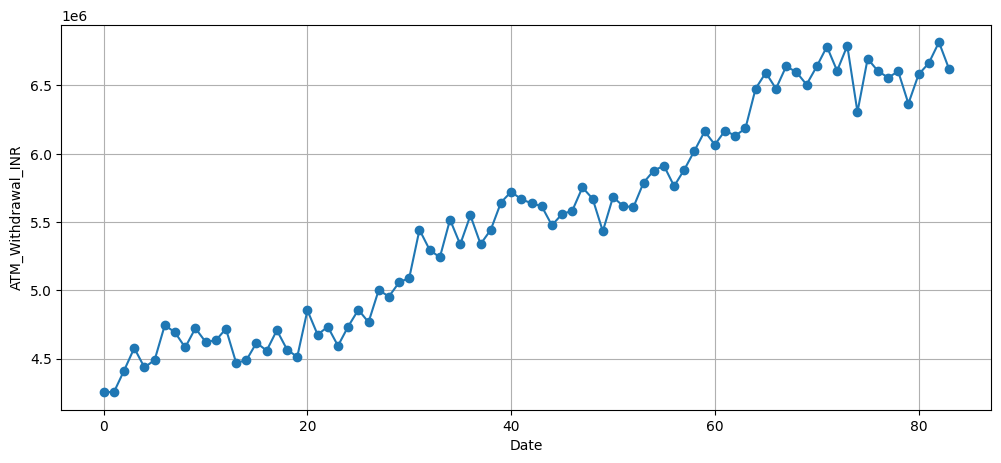

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(df.index,df["ATM_Withdrawal_INR"],marker='o')

plt.xlabel("Date")
plt.ylabel("ATM_Withdrawal_INR")
plt.grid(True)
plt.show()

Train 72
Train 12


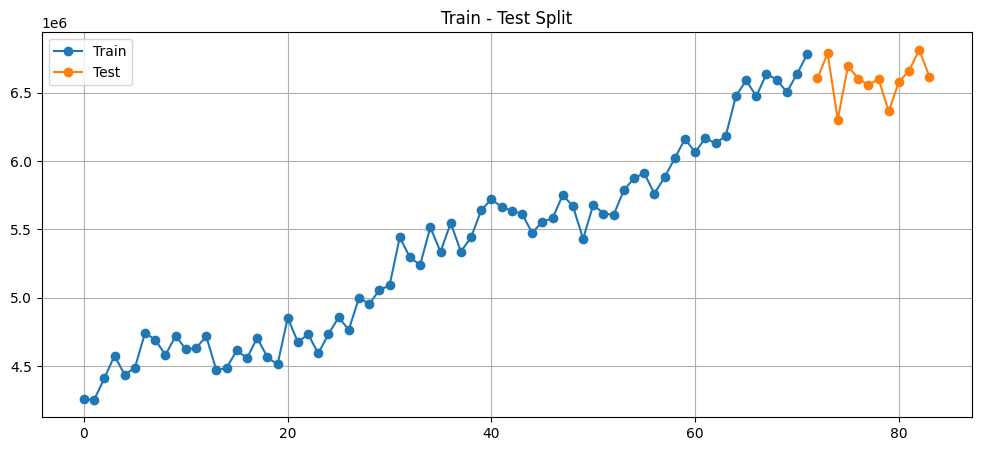

In [26]:
train = df["ATM_Withdrawal_INR"].iloc[:72]
test = df["ATM_Withdrawal_INR"].iloc[72:]

print("Train",len(train))
print("Train",len(test))

plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label="Train",marker="o")
plt.plot(test.index, test, label="Test",marker="o")
plt.title("Train - Test Split")
plt.legend()
plt.grid(True)
plt.show()



In [32]:
from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(train,
                 order = (1, 1, 1)
)

#Fit the MA model
arima_result = arima_model.fit()

In [34]:
arima_forecast = arima_result.forecast(steps=12)
print(arima_forecast)

84    6.627730e+06
85    6.625157e+06
86    6.625797e+06
87    6.625638e+06
88    6.625678e+06
89    6.625668e+06
90    6.625670e+06
91    6.625670e+06
92    6.625670e+06
93    6.625670e+06
94    6.625670e+06
95    6.625670e+06
Name: predicted_mean, dtype: float64


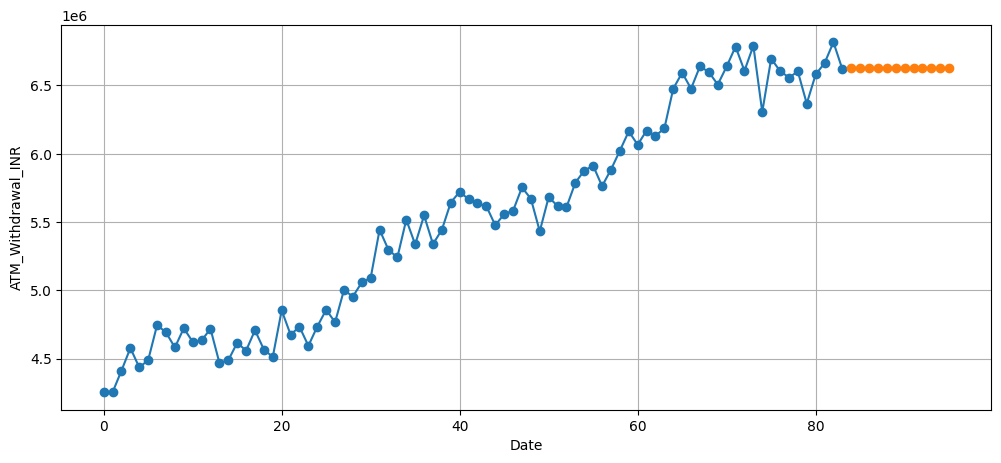

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(df.index,df["ATM_Withdrawal_INR"],marker='o')
plt.plot(arima_forecast.index,arima_forecast,marker='o')

plt.xlabel("Date")
plt.ylabel("ATM_Withdrawal_INR")
plt.grid(True)
plt.show()